In [1]:
# 1. Imports and configuration
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from scipy.sparse import csr_matrix, hstack

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20

In [2]:
# 2. Load and inspect the dataset
DATA_PATH = Path("/home/maryam/Downloads/EMSCAD_Project/data/raw/DataSet.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH.resolve()}\n"
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nTarget distribution:")
print(df["fraudulent"].value_counts(dropna=False))
print("\nMissing values:")
display(df.isna().sum().to_frame("Missing values"))

Dataset shape: (17880, 18)
Columns: ['title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent', 'in_balanced_dataset']

Target distribution:
fraudulent
f    17014
t      866
Name: count, dtype: int64

Missing values:


,Missing values
title,0
location,346
department,11547
salary_range,15012
company_profile,3308
description,0
requirements,2689
benefits,7196
telecommuting,0
has_company_logo,0


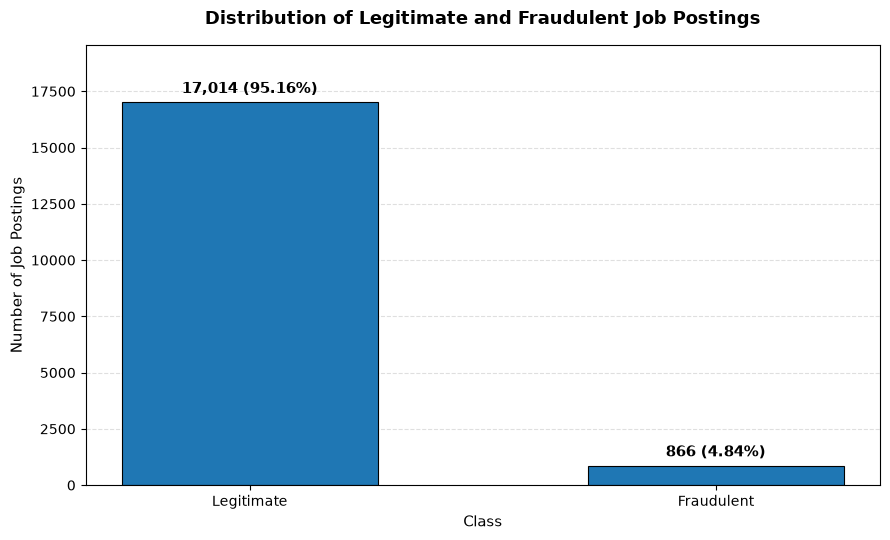

In [3]:
import textwrap

# Prepare target variable
target_labels = df["fraudulent"].map({
    "f": "Legitimate",
    "t": "Fraudulent"
})

class_counts = target_labels.value_counts().reindex(
    ["Legitimate", "Fraudulent"]
)

class_percentages = (
    class_counts / class_counts.sum()
) * 100

# Create figure
fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    class_counts.index,
    class_counts.values,
    width=0.55,
    edgecolor="black",
    linewidth=0.8
)

# Add count and percentage labels
for bar, count, percentage in zip(
    bars, class_counts.values, class_percentages.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 250,
        f"{count:,} ({percentage:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Distribution of Legitimate and Fraudulent Job Postings",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Class", fontsize=11)
ax.set_ylabel("Number of Job Postings", fontsize=11)

ax.set_ylim(0, class_counts.max() * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "Figure_3_2_Class_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

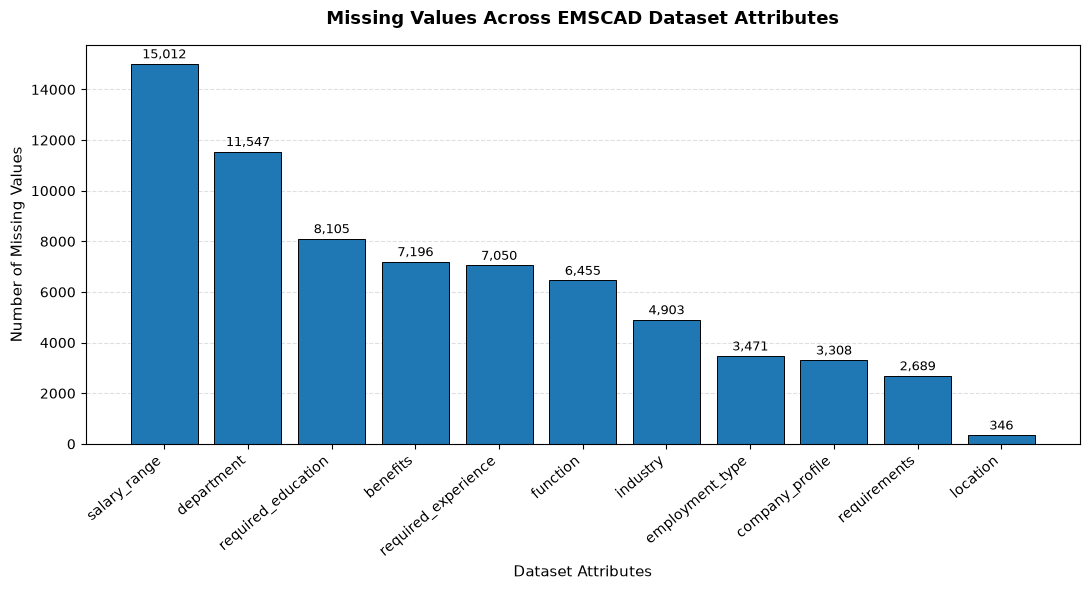

In [4]:
# Calculate missing values
missing_counts = df.isnull().sum()

# Keep only columns containing missing values
missing_counts = missing_counts[
    missing_counts > 0
].sort_values(ascending=False)

# Create figure
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    missing_counts.index,
    missing_counts.values,
    edgecolor="black",
    linewidth=0.7
)

# Add count labels
for bar, count in zip(bars, missing_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title(
    "Missing Values Across EMSCAD Dataset Attributes",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Dataset Attributes", fontsize=11)
ax.set_ylabel("Number of Missing Values", fontsize=11)

plt.xticks(rotation=40, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "Figure_3_3_Missing_Values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

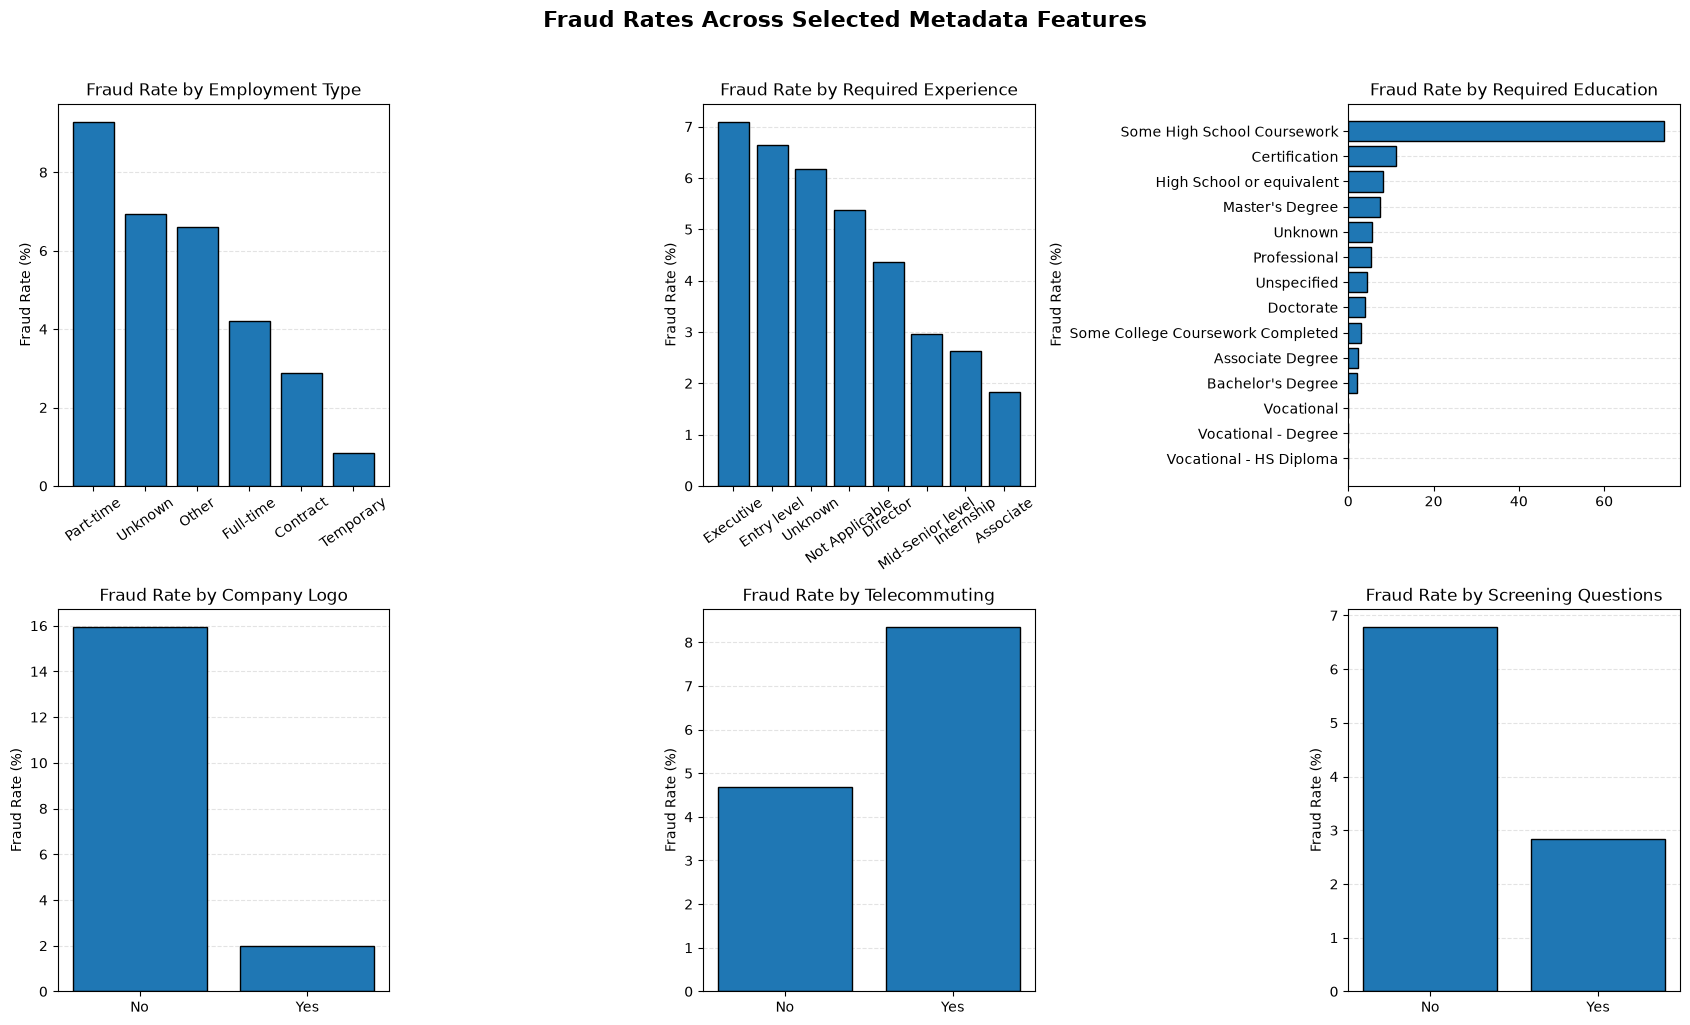

In [5]:
# Prepare a copy for analysis
eda_df = df.copy()

# Convert target variable into numerical values
eda_df["fraudulent_numeric"] = eda_df["fraudulent"].map({
    "f": 0,
    "t": 1
})

# Selected metadata features
categorical_features = [
    "employment_type",
    "required_experience",
    "required_education"
]

binary_features = [
    "has_company_logo",
    "telecommuting",
    "has_questions"
]

# Convert binary attributes into readable labels
binary_labels = {
    "f": "No",
    "t": "Yes"
}

for feature in binary_features:
    eda_df[feature] = eda_df[feature].map(binary_labels)


# Calculate fraud rates for categorical features
def calculate_fraud_rate(data, feature):
    result = (
        data.groupby(feature, dropna=False)["fraudulent_numeric"]
        .agg(["mean", "count"])
        .reset_index()
    )

    result["fraud_rate"] = result["mean"] * 100

    result[feature] = result[feature].fillna("Unknown")

    return result.sort_values(
        "fraud_rate",
        ascending=False
    )


# Create 2 x 3 layout
fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10)
)

fig.suptitle(
    "Fraud Rates Across Selected Metadata Features",
    fontsize=16,
    fontweight="bold",
    y=1.02
)


# Employment type
employment_data = calculate_fraud_rate(
    eda_df, "employment_type"
)

axes[0, 0].bar(
    employment_data["employment_type"].astype(str),
    employment_data["fraud_rate"],
    edgecolor="black"
)

axes[0, 0].set_title("Fraud Rate by Employment Type")


# Required experience
experience_data = calculate_fraud_rate(
    eda_df, "required_experience"
)

axes[0, 1].bar(
    experience_data["required_experience"].astype(str),
    experience_data["fraud_rate"],
    edgecolor="black"
)

axes[0, 1].set_title("Fraud Rate by Required Experience")


# Required education
education_data = calculate_fraud_rate(
    eda_df, "required_education"
)

axes[0, 2].barh(
    education_data["required_education"].astype(str),
    education_data["fraud_rate"],
    edgecolor="black"
)

axes[0, 2].set_title("Fraud Rate by Required Education")
axes[0, 2].invert_yaxis()


# Binary features
binary_titles = {
    "has_company_logo": "Fraud Rate by Company Logo",
    "telecommuting": "Fraud Rate by Telecommuting",
    "has_questions": "Fraud Rate by Screening Questions"
}

binary_axes = [
    axes[1, 0],
    axes[1, 1],
    axes[1, 2]
]

for feature, ax in zip(binary_features, binary_axes):

    binary_data = calculate_fraud_rate(
        eda_df, feature
    )

    # Display No before Yes
    binary_data[feature] = pd.Categorical(
        binary_data[feature],
        categories=["No", "Yes"],
        ordered=True
    )

    binary_data = binary_data.sort_values(feature)

    ax.bar(
        binary_data[feature].astype(str),
        binary_data["fraud_rate"],
        edgecolor="black"
    )

    ax.set_title(binary_titles[feature])


# Format all subplots
for ax in axes.flat:
    ax.set_ylabel("Fraud Rate (%)")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

# Rotate labels for the categorical charts
for ax in [axes[0, 0], axes[0, 1]]:
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()

plt.savefig(
    "Figure_3_4_Metadata_Fraud_Rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
# 3. Remove duplicates and exclude unsuitable attributes
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
rows_after = len(df)

print("Rows before duplicate removal:", rows_before)
print("Rows after duplicate removal:", rows_after)
print("Duplicates remaining:", df.duplicated().sum())

excluded_columns = ["salary_range", "in_balanced_dataset"]
df = df.drop(columns=excluded_columns)

print("\nWorking dataset shape:", df.shape)
print("Remaining columns:", df.columns.tolist())

Rows before duplicate removal: 17880
Rows after duplicate removal: 17645
Duplicates remaining: 0

Working dataset shape: (17645, 16)
Remaining columns: ['title', 'location', 'department', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']


In [7]:
# 4. Separate target and create the train/test split
X = df.drop(columns=["fraudulent"]).copy()
y = df["fraudulent"].map({"f": 0, "t": 1})

if y.isna().any():
    raise ValueError("Unexpected or missing values were found in the target column.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training set: (14116, 15)
Testing set: (3529, 15)

Training class distribution:
fraudulent
0    13430
1      686
Name: count, dtype: int64

Testing class distribution:
fraudulent
0    3357
1     172
Name: count, dtype: int64


In [8]:
# 5. Text preparation
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

X_train_text = X_train[text_columns].copy()
X_test_text = X_test[text_columns].copy()

X_train_text = X_train_text.fillna("")
X_test_text = X_test_text.fillna("")

train_combined_text = X_train_text.agg(" ".join, axis=1)
test_combined_text = X_test_text.agg(" ".join, axis=1)

def clean_text(text):
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"&[a-zA-Z]+;", " ", text)
    text = text.lower()
    text = re.sub(r"#url_[a-z0-9]+#", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

X_train_clean_text = train_combined_text.apply(clean_text)
X_test_clean_text = test_combined_text.apply(clean_text)

print("Example of cleaned training text:")
print(X_train_clean_text.iloc[0][:1000])

Example of cleaned training text:
community manager cashie commerce is the fastest way to create and run a successful online store our goal is to help small businesses launch high quality stores and generate sales in little time we do this by automating features that maximize a store s reach and offering integrated marketing and sales tools to effectively drive sales with just a few clicks a merchant can sell on their own website facebook business page mobile device and our bitdazzle marketplace destination site this includes any kind of product physical digital services and donations and unlimited products and variations cashie commerce also partners with paypal to ensure secure and reliable payments we re funded by all star investors such as tech coast angels 500 startups have great benefits and a collaborative work environment in the heart of downtown san diego if you have an entrepeneurial spirit and want to join a fun fast growing team then we d love to hear from you the cashie co

In [9]:
import nltk

nltk.download("wordnet")
nltk.download("omw-1.4")

from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    tokens = text.split()
    return " ".join(lemmatizer.lemmatize(token) for token in tokens)

X_train_lemmatized = X_train_clean_text.apply(lemmatize_text)
X_test_lemmatized = X_test_clean_text.apply(lemmatize_text)

print("Before lemmatization:")
print(X_train_clean_text.iloc[0][:500])
print("\nAfter lemmatization:")
print(X_train_lemmatized.iloc[0][:500])

[nltk_data] Downloading package wordnet to /home/maryam/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/maryam/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Before lemmatization:
community manager cashie commerce is the fastest way to create and run a successful online store our goal is to help small businesses launch high quality stores and generate sales in little time we do this by automating features that maximize a store s reach and offering integrated marketing and sales tools to effectively drive sales with just a few clicks a merchant can sell on their own website facebook business page mobile device and our bitdazzle marketplace destination site this includes an

After lemmatization:
community manager cashie commerce is the fastest way to create and run a successful online store our goal is to help small business launch high quality store and generate sale in little time we do this by automating feature that maximize a store s reach and offering integrated marketing and sale tool to effectively drive sale with just a few click a merchant can sell on their own website facebook business page mobile device and our bitdazzle marketpla

In [10]:
# 6. TF-IDF feature extraction
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_lemmatized)
X_test_tfidf = tfidf.transform(X_test_lemmatized)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (14116, 10000)
Test TF-IDF shape: (3529, 10000)


In [11]:
# 7. Categorical feature processing
other_cat_cols = [
    "department",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

def split_location(frame):
    parts = frame["location"].fillna("Unknown").str.split(
        ",", n=2, expand=True
    )
    parts = parts.reindex(columns=range(3))
    parts.columns = ["country", "region", "city"]

    for column in ["country", "region", "city"]:
        parts[column] = (
            parts[column]
            .fillna("Unknown")
            .astype(str)
            .str.strip()
            .replace("", "Unknown")
        )
    return parts

train_location = split_location(X_train)
test_location = split_location(X_test)

train_other_cat = X_train[other_cat_cols].copy().fillna("Unknown")
test_other_cat = X_test[other_cat_cols].copy().fillna("Unknown")

X_train_cat_final = pd.concat(
    [train_location, train_other_cat], axis=1
)
X_test_cat_final = pd.concat(
    [test_location, test_other_cat], axis=1
)

ohe_final = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

X_train_cat_ohe = ohe_final.fit_transform(X_train_cat_final)
X_test_cat_ohe = ohe_final.transform(X_test_cat_final)

print("Categorical columns:", X_train_cat_final.columns.tolist())
print("Training categorical OHE:", X_train_cat_ohe.shape)
print("Testing categorical OHE:", X_test_cat_ohe.shape)

Categorical columns: ['country', 'region', 'city', 'department', 'employment_type', 'required_experience', 'required_education', 'industry', 'function']
Training categorical OHE: (14116, 3791)
Testing categorical OHE: (3529, 3791)


In [12]:
# 8. Binary features and missing-value indicators
binary_cols = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]
binary_map = {"f": 0, "t": 1}

X_train_binary = X_train[binary_cols].replace(binary_map).astype("int8")
X_test_binary = X_test[binary_cols].replace(binary_map).astype("int8")

X_train_binary_sparse = csr_matrix(X_train_binary.to_numpy())
X_test_binary_sparse = csr_matrix(X_test_binary.to_numpy())

missing_feature_cols = [
    "company_profile",
    "employment_type",
    "required_experience"
]

missing_feature_names = [
    "company_profile_missing",
    "employment_type_missing",
    "required_experience_missing"
]

X_train_missing = X_train[missing_feature_cols].isna().astype("int8")
X_test_missing = X_test[missing_feature_cols].isna().astype("int8")

X_train_missing.columns = missing_feature_names
X_test_missing.columns = missing_feature_names

X_train_missing_sparse = csr_matrix(X_train_missing.to_numpy())
X_test_missing_sparse = csr_matrix(X_test_missing.to_numpy())

print("Binary features:", X_train_binary_sparse.shape)
print("Missingness features:", X_train_missing_sparse.shape)

Binary features: (14116, 3)
Missingness features: (14116, 3)


In [13]:
# 9. Construct the final hybrid feature matrices
X_train_hybrid = hstack([
    X_train_tfidf,
    X_train_cat_ohe,
    X_train_binary_sparse,
    X_train_missing_sparse
]).tocsr()

X_test_hybrid = hstack([
    X_test_tfidf,
    X_test_cat_ohe,
    X_test_binary_sparse,
    X_test_missing_sparse
]).tocsr()

expected_features = (
    X_train_tfidf.shape[1]
    + X_train_cat_ohe.shape[1]
    + X_train_binary_sparse.shape[1]
    + X_train_missing_sparse.shape[1]
)

assert X_train_hybrid.shape[1] == expected_features
assert X_test_hybrid.shape[1] == expected_features
assert X_train_hybrid.shape[1] == X_test_hybrid.shape[1]

print("TF-IDF features:", X_train_tfidf.shape[1])
print("Categorical OHE features:", X_train_cat_ohe.shape[1])
print("Binary features:", X_train_binary_sparse.shape[1])
print("Missingness features:", X_train_missing_sparse.shape[1])
print("Total hybrid features:", X_train_hybrid.shape[1])
print("Training matrix:", X_train_hybrid.shape)
print("Testing matrix:", X_test_hybrid.shape)

TF-IDF features: 10000
Categorical OHE features: 3791
Binary features: 3
Missingness features: 3
Total hybrid features: 13797
Training matrix: (14116, 13797)
Testing matrix: (3529, 13797)


In [14]:
# 10. Handle class imbalance for the individual classifiers
print("Training distribution before SMOTE:")
print(y_train.value_counts().sort_index())

smote = SMOTE(
    random_state=RANDOM_STATE,
    sampling_strategy="auto"
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_hybrid,
    y_train
)

print("\nTraining distribution after SMOTE:")
print(pd.Series(y_train_smote).value_counts().sort_index())
print("\nBefore SMOTE:", X_train_hybrid.shape)
print("After SMOTE:", X_train_smote.shape)

Training distribution before SMOTE:
fraudulent
0    13430
1      686
Name: count, dtype: int64

Training distribution after SMOTE:
fraudulent
0    13430
1    13430
Name: count, dtype: int64

Before SMOTE: (14116, 13797)
After SMOTE: (26860, 13797)


In [15]:
# 11. Train the six individual classifiers
# Multinomial Naive Bayes
# The hybrid TF-IDF + metadata matrix contains non-negative values.
nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_train_smote, y_train_smote)

# Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)
lr_model.fit(X_train_smote, y_train_smote)

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight=None
)
rf_model.fit(X_train_smote, y_train_smote)

# Linear Support Vector Machine
svm_model = LinearSVC(
    random_state=RANDOM_STATE,
    max_iter=2000
)
svm_model.fit(X_train_smote, y_train_smote)

# XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=2
)
xgb_model.fit(X_train_smote, y_train_smote)

# LightGBM
# Note: subsample=0.8 is retained from the original configuration.
# LightGBM's default subsample_freq=0 means row subsampling is inactive.
lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    num_leaves=15,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary",
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbosity=-1
)
lgbm_model.fit(X_train_smote, y_train_smote)

print("All six individual classifiers have been trained.")

All six individual classifiers have been trained.


In [16]:
# 12. Generate individual-model predictions and scores
individual_predictions = {
    "Multinomial Naive Bayes": nb_model.predict(X_test_hybrid),
    "Logistic Regression": lr_model.predict(X_test_hybrid),
    "Random Forest": rf_model.predict(X_test_hybrid),
    "Linear SVM": svm_model.predict(X_test_hybrid),
    "XGBoost": xgb_model.predict(X_test_hybrid),
    "LightGBM": lgbm_model.predict(X_test_hybrid)
}

individual_scores = {
    "Multinomial Naive Bayes": nb_model.predict_proba(X_test_hybrid)[:, 1],
    "Logistic Regression": lr_model.predict_proba(X_test_hybrid)[:, 1],
    "Random Forest": rf_model.predict_proba(X_test_hybrid)[:, 1],
    "Linear SVM": svm_model.decision_function(X_test_hybrid),
    "XGBoost": xgb_model.predict_proba(X_test_hybrid)[:, 1],
    "LightGBM": lgbm_model.predict_proba(X_test_hybrid)[:, 1]
}

for model_name in individual_predictions:
    assert len(individual_predictions[model_name]) == len(y_test)
    assert len(individual_scores[model_name]) == len(y_test)

print("Prediction and score lengths match the test-set size.")

Prediction and score lengths match the test-set size.


In [17]:
# 13. Five-fold out-of-fold (OOF) stacking ensemble
#
# OOF predictions are generated only from the original training data.
# SMOTE is applied separately inside each fold to prevent resampling leakage.

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

stack_base_estimators = {
    "lr": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    "svm": LinearSVC(
        random_state=RANDOM_STATE,
        max_iter=5000
    ),
    "lgbm": LGBMClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=4,
        num_leaves=15,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary",
        random_state=RANDOM_STATE,
        n_jobs=2,
        verbosity=-1
    )
}

n_splits = 5
skf = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=RANDOM_STATE
)

y_train_array = np.asarray(y_train)
oof_lr = np.zeros(len(y_train_array), dtype=float)
oof_svm = np.zeros(len(y_train_array), dtype=float)
oof_lgbm = np.zeros(len(y_train_array), dtype=float)

for fold, (train_idx, valid_idx) in enumerate(
    skf.split(X_train_hybrid, y_train_array), start=1
):
    print(f"Processing fold {fold}/{n_splits}...")

    X_fold_train = X_train_hybrid[train_idx]
    X_fold_valid = X_train_hybrid[valid_idx]
    y_fold_train = y_train_array[train_idx]

    # Resample only the current fold's training partition.
    fold_smote = SMOTE(
        random_state=RANDOM_STATE,
        k_neighbors=5
    )
    X_fold_train_smote, y_fold_train_smote = fold_smote.fit_resample(
        X_fold_train,
        y_fold_train
    )

    fold_lr = clone(stack_base_estimators["lr"])
    fold_svm = clone(stack_base_estimators["svm"])
    fold_lgbm = clone(stack_base_estimators["lgbm"])

    fold_lr.fit(X_fold_train_smote, y_fold_train_smote)
    fold_svm.fit(X_fold_train_smote, y_fold_train_smote)
    fold_lgbm.fit(X_fold_train_smote, y_fold_train_smote)

    # Each validation record is scored by models that did not train on it.
    oof_lr[valid_idx] = fold_lr.predict_proba(X_fold_valid)[:, 1]
    oof_svm[valid_idx] = fold_svm.decision_function(X_fold_valid)
    oof_lgbm[valid_idx] = fold_lgbm.predict_proba(X_fold_valid)[:, 1]

    print(
        f"Fold {fold}: training rows={len(train_idx)}, "
        f"validation rows={len(valid_idx)}, "
        f"resampled training rows={X_fold_train_smote.shape[0]}"
    )

# Train the meta-classifier using OOF predictions for all training records.
X_meta_train = pd.DataFrame({
    "lr_score": oof_lr,
    "svm_score": oof_svm,
    "lgbm_score": oof_lgbm
})

meta_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)
meta_model.fit(X_meta_train, y_train_array)

print("\\nOOF meta-feature matrix:", X_meta_train.shape)
print("Meta-classifier trained using five-fold OOF predictions.")

# Refit the base models on the complete SMOTE-resampled training set.
# X_train_smote was created from X_train_hybrid and y_train only;
# the independent test set was not used during resampling.
stack_lr = clone(stack_base_estimators["lr"])
stack_svm = clone(stack_base_estimators["svm"])
stack_lgbm = clone(stack_base_estimators["lgbm"])

stack_lr.fit(X_train_smote, y_train_smote)
stack_svm.fit(X_train_smote, y_train_smote)
stack_lgbm.fit(X_train_smote, y_train_smote)

# Generate test meta-features using the refitted base models.
X_meta_test = pd.DataFrame({
    "lr_score": stack_lr.predict_proba(X_test_hybrid)[:, 1],
    "svm_score": stack_svm.decision_function(X_test_hybrid),
    "lgbm_score": stack_lgbm.predict_proba(X_test_hybrid)[:, 1]
})

y_pred_stack_smote = meta_model.predict(X_meta_test)
y_prob_stack_smote = meta_model.predict_proba(X_meta_test)[:, 1]

print("OOF stacking test predictions generated.")
print("Test predictions:", len(y_pred_stack_smote))
print("Test meta-feature matrix:", X_meta_test.shape)

assert len(oof_lr) == len(y_train_array)
assert len(oof_svm) == len(y_train_array)
assert len(oof_lgbm) == len(y_train_array)
assert len(y_pred_stack_smote) == len(y_test)
assert len(y_prob_stack_smote) == len(y_test)
print("OOF stacking consistency checks passed.")


Processing fold 1/5...
Fold 1: training rows=11292, validation rows=2824, resampled training rows=21488
Processing fold 2/5...
Fold 2: training rows=11293, validation rows=2823, resampled training rows=21488
Processing fold 3/5...
Fold 3: training rows=11293, validation rows=2823, resampled training rows=21488
Processing fold 4/5...
Fold 4: training rows=11293, validation rows=2823, resampled training rows=21488
Processing fold 5/5...
Fold 5: training rows=11293, validation rows=2823, resampled training rows=21488
\nOOF meta-feature matrix: (14116, 3)
Meta-classifier trained using five-fold OOF predictions.
OOF stacking test predictions generated.
Test predictions: 3529
Test meta-feature matrix: (3529, 3)
OOF stacking consistency checks passed.


In [18]:
# 14. Model evaluation
predictions = dict(individual_predictions)
scores = dict(individual_scores)

predictions["SMOTE-Based Stacking"] = y_pred_stack_smote
scores["SMOTE-Based Stacking"] = y_prob_stack_smote

result_rows = []

for model_name in predictions:
    y_pred = predictions[model_name]
    y_score = scores[model_name]

    result_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "Average Precision": average_precision_score(y_test, y_score)
    })

final_results = pd.DataFrame(result_rows)

display(final_results.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Multinomial Naive Bayes,0.9436,0.4595,0.8895,0.6059,0.9729,0.8334
1,Logistic Regression,0.9759,0.6986,0.8895,0.7826,0.9881,0.8898
2,Random Forest,0.9816,0.9652,0.6453,0.7735,0.9888,0.9037
3,Linear SVM,0.9841,0.8452,0.8256,0.8353,0.9873,0.9116
4,XGBoost,0.9745,0.7278,0.7616,0.7443,0.9785,0.8215
5,LightGBM,0.9768,0.7296,0.8314,0.7772,0.9813,0.8612
6,SMOTE-Based Stacking,0.9870,0.8889,0.8372,0.8623,0.9885,0.9193


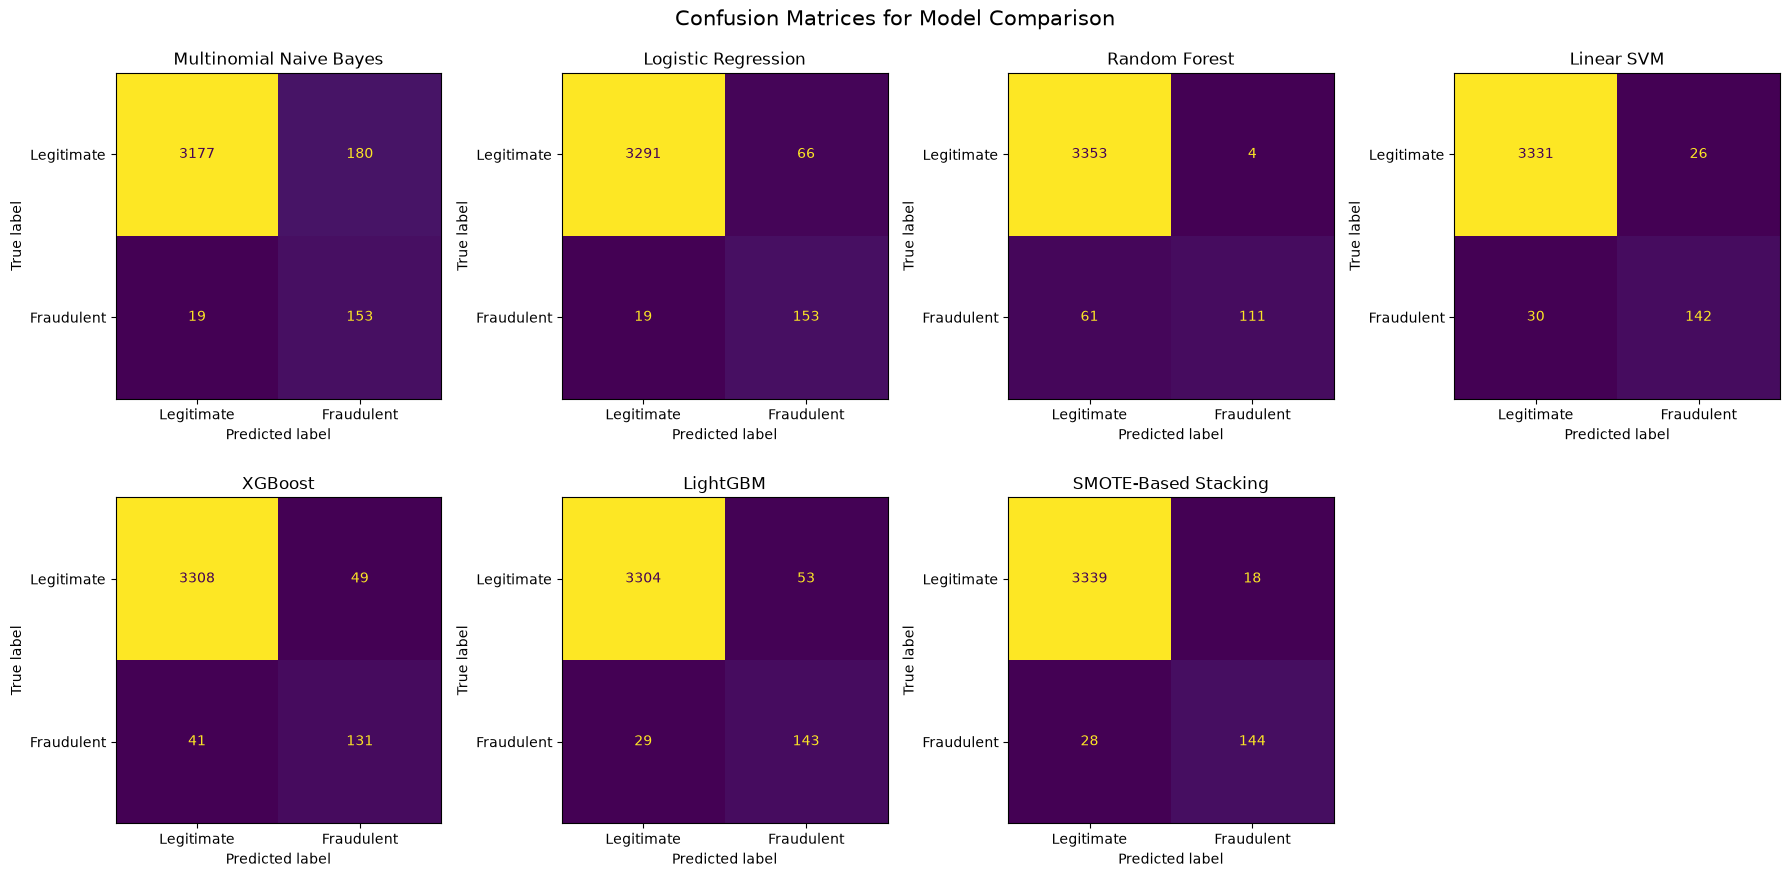

In [19]:
# 15. Confusion matrices
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.ravel()

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Fraudulent"]
    ).plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )
    ax.set_title(model_name)

for ax in axes[len(predictions):]:
    ax.set_visible(False)

plt.suptitle("Confusion Matrices for Model Comparison", fontsize=15)
plt.tight_layout()
plt.show()

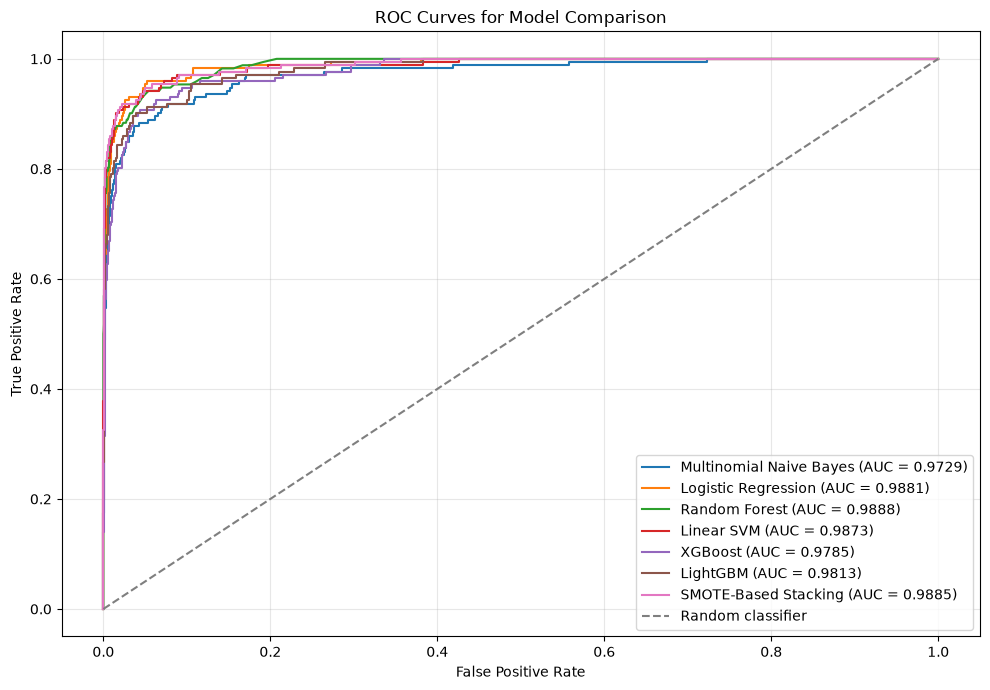

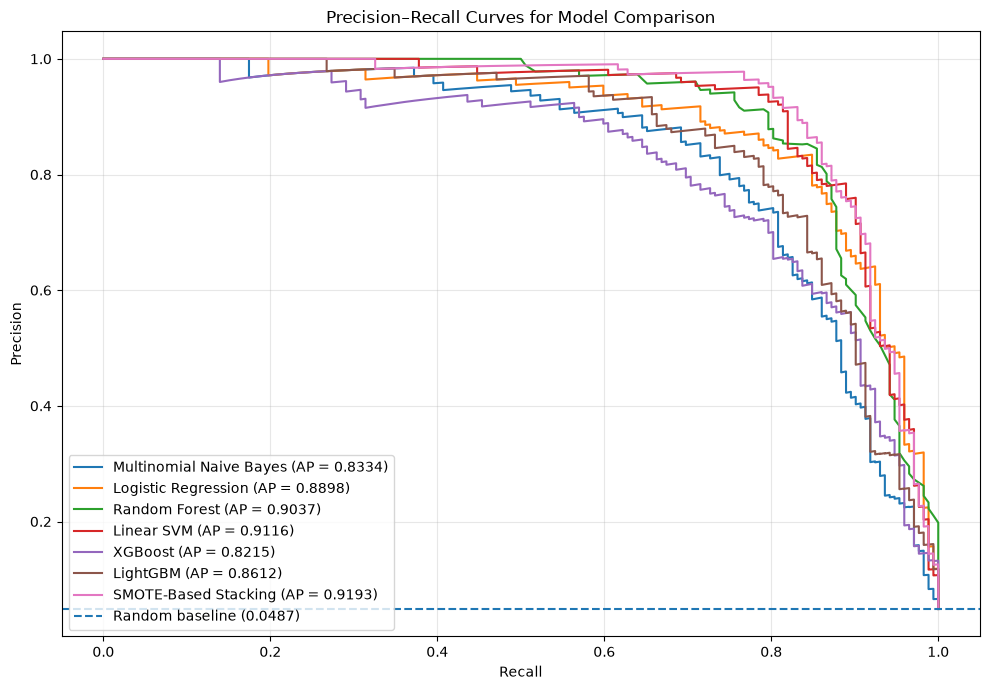

In [20]:
# 16. ROC and Precision-Recall curves

# ROC Curve
plt.figure(figsize=(10, 7))

for model_name, y_score in scores.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc_value = roc_auc_score(y_test, y_score)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc_value:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.title("ROC Curves for Model Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))

for model_name, y_score in scores.items():
    precision, recall, _ = precision_recall_curve(y_test, y_score)
    ap_value = average_precision_score(y_test, y_score)
    plt.plot(recall, precision, label=f"{model_name} (AP = {ap_value:.4f})")

fraud_rate = y_test.mean()
plt.axhline(
    y=fraud_rate,
    linestyle="--",
    label=f"Random baseline ({fraud_rate:.4f})"
)
plt.title("Precision–Recall Curves for Model Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

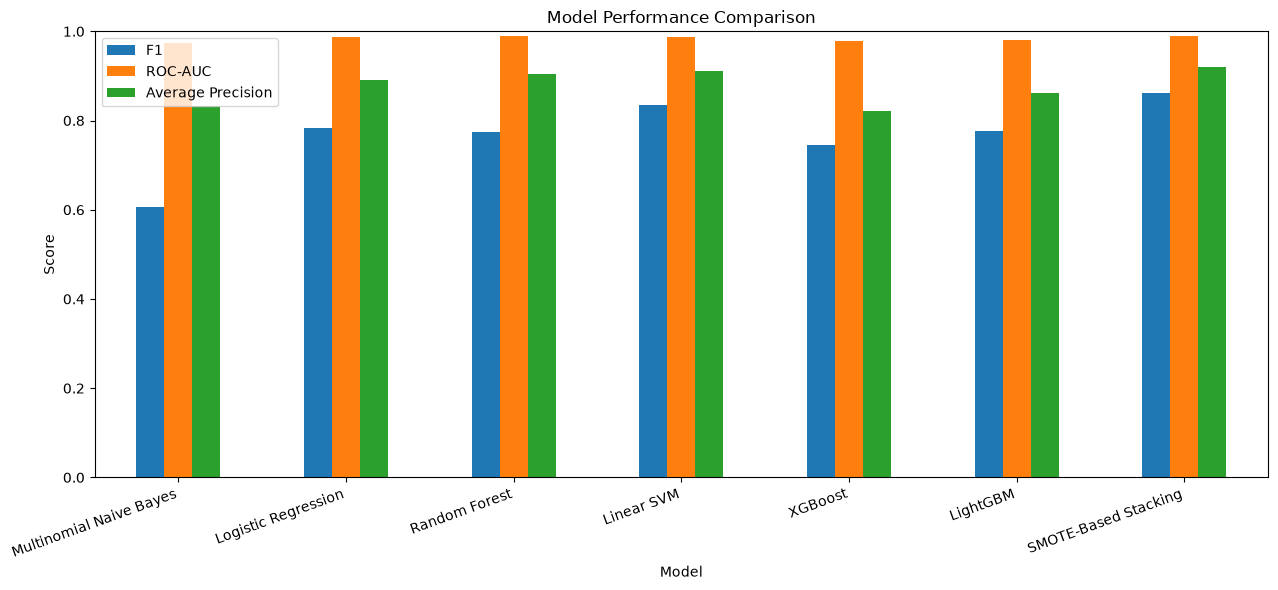

In [21]:
# 17. Compare the principal evaluation metrics
plot_results = final_results.set_index("Model")[[
    "F1", "ROC-AUC", "Average Precision"
]]

ax = plot_results.plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1)
)
ax.set_title("Model Performance Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [22]:
# 18. Model explainability using SHAP
import shap

tfidf_feature_names = tfidf.get_feature_names_out()
categorical_feature_names = ohe_final.get_feature_names_out()

binary_feature_names = np.array(binary_cols)
missing_feature_names_array = np.array(missing_feature_names)

feature_names = np.concatenate([
    tfidf_feature_names,
    categorical_feature_names,
    binary_feature_names,
    missing_feature_names_array
])

assert len(feature_names) == X_test_hybrid.shape[1]

X_shap = X_test_hybrid[:200]
X_shap_dense = X_shap.toarray()

print("SHAP sample shape:", X_shap_dense.shape)
print("Feature-name count:", len(feature_names))

SHAP sample shape: (200, 13797)
Feature-name count: 13797


In [23]:
explainer = shap.TreeExplainer(lgbm_model)
shap_values_raw = explainer.shap_values(X_shap_dense)

# Normalize output shape across SHAP versions for binary classification.
if isinstance(shap_values_raw, list):
    shap_values = np.asarray(shap_values_raw[1])
else:
    shap_values = np.asarray(shap_values_raw)
    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, 1]

assert shap_values.shape == X_shap_dense.shape

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs_shap
}).sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

display(shap_importance.head(20))

/home/maryam/EMSCAD_Project/.venv/lib/python3.11/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,feature,mean_abs_shap
0,company_profile_missing,0.762571
1,has_company_logo,0.366360
2,country_US,0.232180
3,required_education_High School or equivalent,0.207173
4,growing,0.168799
5,are encouraged,0.166260
6,has_questions,0.158151
7,of our,0.147408
8,earn,0.136568
9,and,0.130286


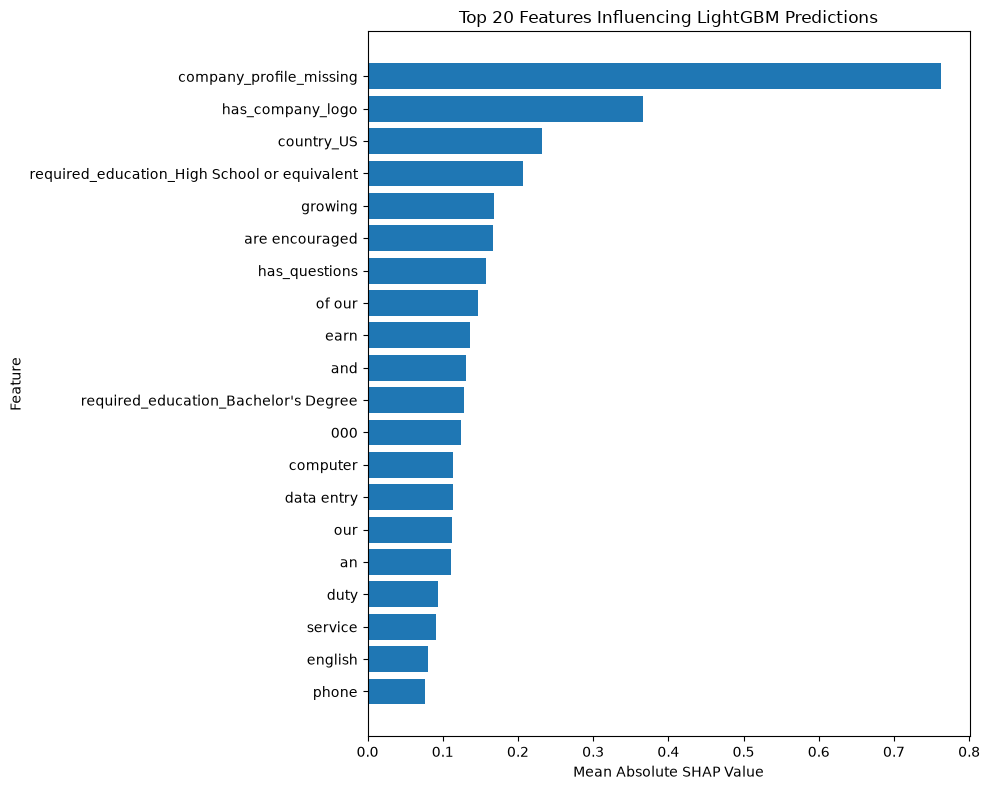

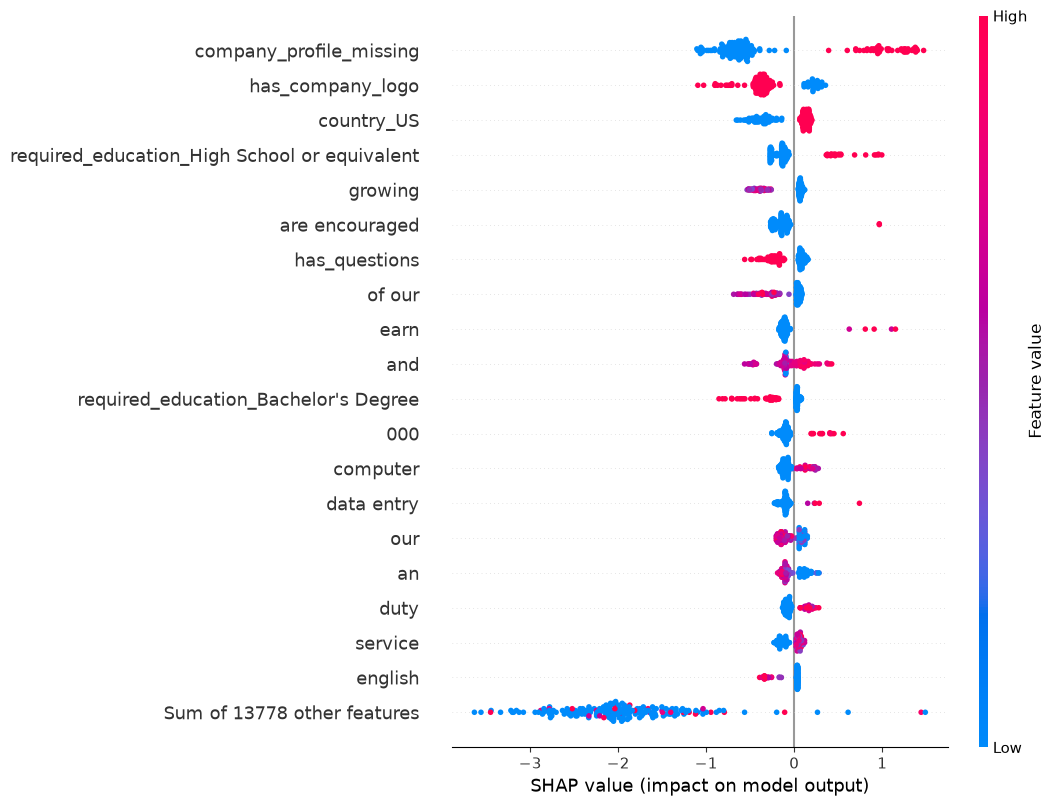

In [24]:
top20 = shap_importance.head(20).sort_values(
    "mean_abs_shap",
    ascending=True
)

plt.figure(figsize=(10, 8))
plt.barh(top20["feature"], top20["mean_abs_shap"])
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 20 Features Influencing LightGBM Predictions")
plt.tight_layout()
plt.show()

shap_explanation = shap.Explanation(
    values=shap_values,
    data=X_shap_dense,
    feature_names=feature_names
)
shap.plots.beeswarm(shap_explanation, max_display=20)

In [25]:
# 19. Final consistency checks
print("=== FINAL PIPELINE CHECK ===")
print("Training hybrid matrix:", X_train_hybrid.shape)
print("Testing hybrid matrix:", X_test_hybrid.shape)
print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))
print("SMOTE training matrix:", X_train_smote.shape)
print("SMOTE labels:", len(y_train_smote))
print("Number of models evaluated:", len(final_results))
print("Test fraud cases:", int(y_test.sum()))

assert X_train_hybrid.shape[1] == X_test_hybrid.shape[1]
assert len(y_test) == X_test_hybrid.shape[0]
assert all(len(pred) == len(y_test) for pred in predictions.values())
assert all(len(score) == len(y_test) for score in scores.values())

print("\nFinal results:")
display(final_results.round(4))

=== FINAL PIPELINE CHECK ===
Training hybrid matrix: (14116, 13797)
Testing hybrid matrix: (3529, 13797)
Training labels: 14116
Testing labels: 3529
SMOTE training matrix: (26860, 13797)
SMOTE labels: 26860
Number of models evaluated: 7
Test fraud cases: 172

Final results:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Multinomial Naive Bayes,0.9436,0.4595,0.8895,0.6059,0.9729,0.8334
1,Logistic Regression,0.9759,0.6986,0.8895,0.7826,0.9881,0.8898
2,Random Forest,0.9816,0.9652,0.6453,0.7735,0.9888,0.9037
3,Linear SVM,0.9841,0.8452,0.8256,0.8353,0.9873,0.9116
4,XGBoost,0.9745,0.7278,0.7616,0.7443,0.9785,0.8215
5,LightGBM,0.9768,0.7296,0.8314,0.7772,0.9813,0.8612
6,SMOTE-Based Stacking,0.9870,0.8889,0.8372,0.8623,0.9885,0.9193
